# Product Review Sentiment — End-to-End NLP Notebook

**Business problem:** *ShopKart*, a fictional e-commerce company, receives thousands of product reviews every week.
The product team wants every review **automatically tagged as positive, neutral or negative**, and wants to see
**which words drove each decision**, so they can trust the tags and spot recurring complaints (for example
"battery dies fast" or "size runs small").

**What we build:**
1. a shared text-cleaning function (`backend/text_utils.py`) used by both this notebook and the API,
2. TF-IDF features (word n-grams and character n-grams) and three linear classifiers,
3. a saved pipeline + `models/sentiment_info.json` that the Flask API uses to analyse one review or a batch.

**Methods practised:** NLP fundamentals (Batch 2 Module 07): text cleaning, tokenisation, bag-of-words and TF-IDF,
n-grams, linear text classifiers (Logistic Regression, Linear SVM, Multinomial Naive Bayes), plus stratified
cross-validation and macro-F1 for an imbalanced 3-class problem.

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
jupyter notebook notebook/Product_Review_Sentiment.ipynb
```

The whole notebook runs in about a minute on a laptop. The first code cell moves to the project root automatically if
you started Jupyter inside `notebook/`.

In [1]:
import os, sys, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, GridSearchCV,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score)

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())

# The cleaning function lives in backend/text_utils.py so the API uses EXACTLY the same code.
sys.path.insert(0, os.path.abspath("backend"))
from text_utils import clean_text

RANDOM_STATE = 42
LABELS = ["negative", "neutral", "positive"]     # fixed order used in every table and plot
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/NLP_Projects/01_Product_Review_Sentiment


## 1. Load the data and look at it

### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `review_id` | Review identifier (not a feature) | text |
| `product_category` | electronics, clothing, home, beauty or grocery | category |
| `review_text` | What the customer wrote — **the only input to our model** | free text |
| `rating` | Star rating 1–5 the customer gave | integer |
| `verified_purchase` | Did the reviewer actually buy the product on ShopKart? | True / False |
| `review_date` | Date the review was posted (2024–2025) | date |
| **`sentiment`** | **Target**: positive, neutral or negative, tagged by a human annotator | category |

The data is synthetic (generated by `data/generate_data.py` with a fixed seed). It was written to be messy in realistic
ways: negations ("not bad", "not worth it"), mixed reviews ("great screen but battery dies fast"), a little sarcasm,
Hinglish words ("bahut accha", "bekaar"), emojis, typos, empty reviews, duplicates and some wrong labels.

In [2]:
df = pd.read_csv("data/product_reviews.csv")
print("Shape:", df.shape)
df.head(8)

Shape: (4060, 7)


,review_id,product_category,review_text,rating,verified_purchase,review_date,sentiment
0,R03286,home,Bought this bedsheet last month. It leaks from the bottom. Not as described.,1,True,2025-10-05,negative
1,R02719,electronics,"theek thaak hai, kuch khaas nahi. 😐",2,True,2024-06-10,neutral
2,R01412,grocery,There were insects in it. Not as described. 🤬,1,True,2025-04-28,negative
3,R00747,clothing,Exceeded my expectations. ❤️,3,True,2024-06-18,positive
4,R01980,electronics,The keyboard is okay. Sound is fine for calls.,2,True,2024-05-30,neutral
5,R00535,electronics,Very light and easy to carry although stopped working after a week. Packaging was standard.,5,True,2024-08-06,neutral
6,R00167,beauty,"The fragrance fades in minutes, but the fragrance lasts long.",5,False,2024-05-30,positive
7,R02620,grocery,It was well packed. Amazing product.,5,True,2024-03-01,positive


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4060 entries, 0 to 4059
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   review_id          4060 non-null   str  
 1   product_category   4060 non-null   str  
 2   review_text        4038 non-null   str  
 3   rating             4060 non-null   int64
 4   verified_purchase  4060 non-null   bool 
 5   review_date        4060 non-null   str  
 6   sentiment          4060 non-null   str  
dtypes: bool(1), int64(1), str(5)
memory usage: 194.4 KB


In [4]:
print("Missing review_text:", df["review_text"].isna().sum())
print("Blank review_text (only spaces):", (df["review_text"].fillna("x").str.strip() == "").sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate review_ids:", df["review_id"].duplicated().sum())

Missing review_text: 22
Blank review_text (only spaces): 13
Duplicate rows: 60
Duplicate review_ids: 60


## 2. Clean the data

1. **Duplicate rows** are the same review exported twice. If we kept them, one copy could land in the training set and
   the other in the test set, and the model would be tested on a review it has already memorised. Drop them first.
2. **Empty reviews** (missing or only spaces) have no text, so a text model can learn nothing from them. The customer
   only left stars. We remove them from training; the API rejects empty text with a clear message.

In [5]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows")

is_empty = df["review_text"].isna() | (df["review_text"].fillna("").str.strip() == "")
print(f"Removed {is_empty.sum()} empty reviews")
df = df[~is_empty].reset_index(drop=True)
print("Rows left:", len(df))

Removed 60 duplicate rows
Removed 35 empty reviews
Rows left: 3965


## 3. Explore the data

### 3.1 Class balance

sentiment
negative    29.1 %
neutral     22.0 %
positive    48.9 %
Name: count, dtype: str


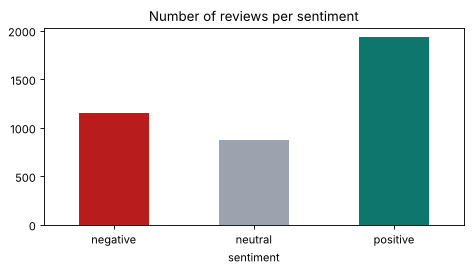

In [6]:
counts = df["sentiment"].value_counts().reindex(LABELS)
print((counts / len(df) * 100).round(1).astype(str) + " %")
counts.plot.bar(color=["#b91c1c", "#9ca3af", "#0f766e"], figsize=(6, 3.5), rot=0,
                title="Number of reviews per sentiment")
plt.tight_layout()

About half of the reviews are positive and only about a fifth are neutral. The classes are **imbalanced**, so plain
accuracy would hide poor performance on the small neutral class. We will use **macro-F1**: the F1-score is computed for
each class separately and then averaged, so every class counts equally.

### 3.2 Do the star ratings agree with the labels?

In [7]:
pd.crosstab(df["rating"], df["sentiment"])[LABELS]

sentiment,negative,neutral,positive
rating,,,
1,627,44,23
2,370,137,39
3,93,472,109
4,35,156,624
5,30,64,1142


Mostly yes: 1–2 stars are mostly negative, 3 stars mostly neutral, 4–5 stars mostly positive. But the table is not
perfectly clean: there are, for example, some 4–5 star reviews labelled negative. People click stars carelessly and
annotators make mistakes. That is **label noise**, and it means no model can reach 100% on this data.

We do **not** use `rating` as a feature. The goal is to understand the *text* (for example, reviews from social media or
support e-mails have no stars), and the API only receives text.

### 3.3 Text length

           mean   50%  min   max
sentiment                       
negative    9.6   9.0  1.0  25.0
neutral    10.3  10.0  1.0  24.0
positive   10.2  10.0  1.0  27.0


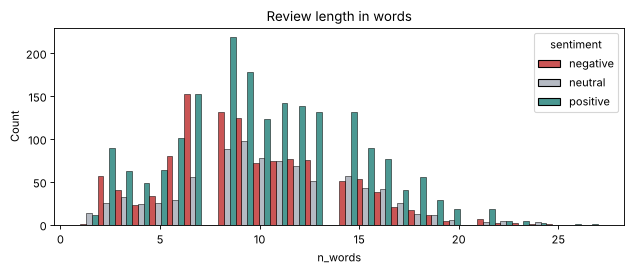

In [8]:
df["n_words"] = df["review_text"].str.split().str.len()
print(df.groupby("sentiment")["n_words"].describe()[["mean", "50%", "min", "max"]].reindex(LABELS).round(1))
plt.figure(figsize=(8, 3.5))
sns.histplot(data=df, x="n_words", hue="sentiment", hue_order=LABELS, bins=30, multiple="dodge",
             palette=["#b91c1c", "#9ca3af", "#0f766e"])
plt.title("Review length in words")
plt.tight_layout()

Reviews are short (about 10 words on average, at most 27), like real one- or two-line product reviews. The length is
similar for all three classes, so length alone will not tell us the sentiment — we need the words.

### 3.4 Category, and a look at the hard cases

In [9]:
pd.crosstab(df["product_category"], df["sentiment"], normalize="index").round(2)[LABELS]

sentiment,negative,neutral,positive
product_category,,,
beauty,0.26,0.22,0.52
clothing,0.28,0.23,0.49
electronics,0.30,0.23,0.47
grocery,0.31,0.22,0.47
home,0.30,0.20,0.50


In [10]:
# Reviews that will be hard for a word-counting model
patterns = {"negation (not/never/no)": r"\bnot\b|n't|\bnever\b|\bno\b",
            "contrast (but/however)": r"\bbut\b|\bhowever\b|\balthough\b",
            "Hinglish": r"accha|bekaar|bakwas|theek|paisa|mast|badhiya|chalega",
            "emoji": r"[\U0001F300-\U0001FAFF\u2764]"}
for name, pat in patterns.items():
    mask = df["review_text"].str.contains(pat, case=False, regex=True)
    print(f"{name:26s} {mask.sum():5d} reviews  e.g. {df.loc[mask, 'review_text'].iloc[0]!r}")

negation (not/never/no)      847 reviews  e.g. 'Bought this bedsheet last month. It leaks from the bottom. Not as described.'
contrast (but/however)       564 reviews  e.g. 'Very light and easy to carry although stopped working after a week. Packaging was standard.'
Hinglish                     273 reviews  e.g. 'theek thaak hai, kuch khaas nahi. 😐'
emoji                        606 reviews  e.g. 'theek thaak hai, kuch khaas nahi. 😐'


## 4. Clean the text

Computers do not understand text, so we will turn each review into numbers by counting words. Before counting, we make
the text consistent so that `"GOOD"`, `"good!!!"` and `"gooood"` all count as the same word.

The cleaning function is in `backend/text_utils.py` (imported at the top). It:
- lower-cases everything,
- turns sentiment emojis into words (`😍 → emo_pos`, `😡 → emo_neg`) instead of deleting them,
- expands short forms so negation is always visible (`doesn't → does not`, `can't → can not`),
- squashes letters repeated 3+ times (`sooo → soo`),
- removes punctuation and extra spaces.

**We do not remove stop words.** Standard stop-word lists contain *not*, *no* and *but*, and those words flip the
meaning of a review. Section 8 shows what happens if we remove them.

In [11]:
for raw in ["NOT worth it!!! Battery dies sooo fast 😡",
            "Doesn't work as described. Can't recommend.",
            "Bahut accha product 😍👍",
            "   ", None]:
    print(f"{str(raw)!r:50} -> {clean_text(raw)!r}")

'NOT worth it!!! Battery dies sooo fast 😡'         -> 'not worth it battery dies soo fast emo_neg'
"Doesn't work as described. Can't recommend."      -> 'does not work as described can not recommend'
'Bahut accha product 😍👍'                           -> 'bahut accha product emo_pos emo_pos'
'   '                                              -> ''
'None'                                             -> ''


In [12]:
df["clean"] = df["review_text"].apply(clean_text)
df[["review_text", "clean", "sentiment"]].sample(6, random_state=1)

,review_text,clean,sentiment
787,The sound crackles at high volume. Never buying again.,the sound crackles at high volume never buying again,negative
435,Bad hoodie.,bad hoodie,negative
292,Bought this ceiling fan last month. Smells of burning plastic. Pathetic product.,bought this ceiling fan last month smells of burning plastic pathetic product,positive
2883,My skin looks brighter. Only issue is results take time. Five stars from me.,my skin looks brighter only issue is results take time five stars from me,positive
1006,very light and easy to carry but left earbud stopped working. waste of money.,very light and easy to carry but left earbud stopped working waste of money,negative
3534,Just average. Material is average.,just average material is average,neutral


## 5. Split into train and test sets

We keep 20% of reviews as a **test set** used once at the end. `stratify=y` keeps the same share of positive, neutral and
negative reviews in both parts. All choices (features, model, settings) are made with cross-validation on the training
set only.

Note that the pipeline receives the **raw** `review_text`; cleaning happens inside the pipeline (`preprocessor=clean_text`)
so the saved model cleans new text by itself.

In [13]:
X = df["review_text"]
y = df["sentiment"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", len(X_train), " Test:", len(X_test))
print(y_train.value_counts(normalize=True).reindex(LABELS).round(3).to_dict())

Train: 3172  Test: 793
{'negative': 0.291, 'neutral': 0.22, 'positive': 0.489}


## 6. From text to numbers: TF-IDF

**TF-IDF** gives every word (or n-gram) in a review a score:
- **TF (term frequency):** how often the word appears in *this* review,
- **IDF (inverse document frequency):** words that appear in almost every review (*the*, *it*, *this*) get a low weight,
  rare but informative words (*rashes*, *stale*, *superb*) get a high weight.

We compare three ways of choosing the "terms":
| Features | What a term is | Good at |
|---|---|---|
| word unigrams | single words: `not`, `bad` | simple, easy to explain |
| word 1–2 grams | single words **and pairs**: `not bad`, `worth it` | negation and short phrases |
| char 2–5 grams | pieces of words inside word boundaries: `bat`, `atter`, `ery ` | typos (`battey`), word endings |

Here is what TF-IDF produces for three tiny reviews:

In [14]:
demo = ["not bad at all", "bad quality", "good quality not bad"]
v = TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2))
m = v.fit_transform(demo)
pd.DataFrame(m.toarray(), columns=v.get_feature_names_out(), index=demo).round(2)

,all,at,at all,bad,bad at,bad quality,good,good quality,not,not bad,quality,quality not
not bad at all,0.43,0.43,0.43,0.25,0.43,0.00,0.00,0.00,0.32,0.32,0.00,0.00
bad quality,0.00,0.00,0.00,0.43,0.00,0.72,0.00,0.00,0.00,0.00,0.55,0.00
good quality not bad,0.00,0.00,0.00,0.26,0.00,0.00,0.44,0.44,0.34,0.34,0.34,0.44


Each review becomes one row of numbers, one column per term. Only the bigram columns (`not bad`, `bad quality`)
can tell *"not bad"* apart from *"bad"*. Real reviews give thousands of columns, but most values are 0, so scikit-learn
stores them as a **sparse matrix**.

## 7. Baseline and three models, compared with cross-validation

- **Baseline:** always predict the most common class (positive). Any useful model must beat it.
- **Logistic Regression:** a linear model that gives **probabilities** — needed by the API to show confidence bars.
- **Linear SVM (LinearSVC):** a strong linear text classifier, but it gives scores, not probabilities.
- **Multinomial Naive Bayes:** the classic, very fast text model that assumes words are independent.

For each model we try word unigrams, word 1–2 grams and char 2–5 grams, using **stratified 5-fold cross-validation**
on the training set, and record macro-F1 and accuracy.

In [15]:
def make_vectorizer(kind):
    if kind == "word 1-gram":
        return TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 1), sublinear_tf=True)
    if kind == "word 1-2 gram":
        return TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    if kind == "char 2-5 gram":
        return TfidfVectorizer(preprocessor=clean_text, analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                               sublinear_tf=True)
    raise ValueError(kind)

models = {
    "Logistic Regression": lambda: LogisticRegression(C=5, max_iter=2000, class_weight="balanced"),
    "Linear SVM": lambda: LinearSVC(C=0.5, class_weight="balanced"),
    "Multinomial NB": lambda: MultinomialNB(alpha=0.3),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
base = cross_validate(DummyClassifier(strategy="most_frequent"), X_train, y_train, cv=cv,
                      scoring=["f1_macro", "accuracy"])
rows.append({"model": "Baseline (most frequent)", "features": "-",
             "CV macro-F1": base["test_f1_macro"].mean(), "F1 std": base["test_f1_macro"].std(),
             "CV accuracy": base["test_accuracy"].mean()})
for model_name, make_model in models.items():
    for feat in ["word 1-gram", "word 1-2 gram", "char 2-5 gram"]:
        pipe = Pipeline([("tfidf", make_vectorizer(feat)), ("clf", make_model())])
        s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1_macro", "accuracy"], n_jobs=-1)
        rows.append({"model": model_name, "features": feat,
                     "CV macro-F1": s["test_f1_macro"].mean(), "F1 std": s["test_f1_macro"].std(),
                     "CV accuracy": s["test_accuracy"].mean()})

cv_results = pd.DataFrame(rows).round(3)
cv_results.sort_values("CV macro-F1", ascending=False)

,model,features,CV macro-F1,F1 std,CV accuracy
4,Linear SVM,word 1-gram,0.866,0.014,0.878
6,Linear SVM,char 2-5 gram,0.865,0.017,0.878
5,Linear SVM,word 1-2 gram,0.861,0.016,0.875
1,Logistic Regression,word 1-gram,0.855,0.011,0.867
2,Logistic Regression,word 1-2 gram,0.853,0.012,0.866
3,Logistic Regression,char 2-5 gram,0.851,0.014,0.864
8,Multinomial NB,word 1-2 gram,0.839,0.019,0.857
7,Multinomial NB,word 1-gram,0.836,0.016,0.855
9,Multinomial NB,char 2-5 gram,0.835,0.016,0.852
0,Baseline (most frequent),-,0.219,0.000,0.489


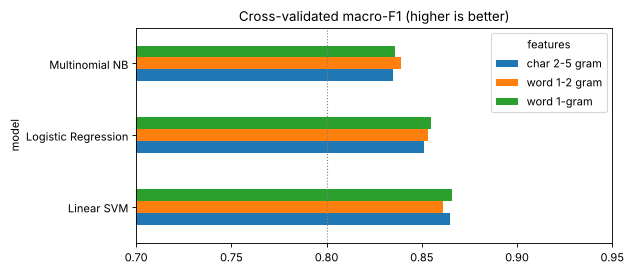

In [16]:
pivot = cv_results[cv_results["features"] != "-"].pivot(index="model", columns="features", values="CV macro-F1")
pivot.plot.barh(figsize=(8, 3.5), xlim=(0.7, 0.95), title="Cross-validated macro-F1 (higher is better)")
plt.axvline(0.8, color="grey", linestyle=":", linewidth=1)
plt.tight_layout()

**Reading the results:**
- The baseline only ever says "positive", so its macro-F1 is very low (it scores 0 on two of the three classes) even
  though its accuracy is around 49%. This is exactly why accuracy alone is misleading here.
- Every real model is far above the baseline, with macro-F1 between about 0.83 and 0.87.
- Linear SVM is slightly ahead, Logistic Regression is about 0.01 behind it, and Naive Bayes about 0.02–0.03 behind.
- The three feature types give almost the same score for each model (differences below 0.01). That is smaller than
  the fold-to-fold variation (`F1 std` about 0.01–0.02), so on this data no feature type is clearly better.

**Our choice for the app:** Logistic Regression with **word 1–2 grams**. It is only about 0.01 behind the best
combination (and tuning `C` below closes most of that gap), but unlike Linear SVM it gives **probabilities**, and its
word-level weights are easy to show to a user. Char n-grams are harder to explain ("`atter`" is not a word a product
manager can act on), and bigrams help with negation (section 8).

### 7.1 Tune the regularisation strength `C`

`C` controls how much the model is allowed to trust individual words: small `C` = simpler, smoother model; large `C` =
follows the training data more closely (risk of overfitting). A small grid search with the same 5 folds:

In [17]:
final_pipe = Pipeline([
    ("tfidf", make_vectorizer("word 1-2 gram")),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
grid = GridSearchCV(final_pipe, {"clf__C": [0.1, 0.25, 0.5, 1, 2, 5, 10]}, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)
print(pd.Series(grid.cv_results_["mean_test_score"], index=grid.cv_results_["param_clf__C"],
                name="CV macro-F1").round(3).to_string())
print("Best C:", grid.best_params_["clf__C"], "| best CV macro-F1:", round(grid.best_score_, 3))
best_model = grid.best_estimator_

0.10     0.855
0.25     0.862
0.50     0.862
1.00     0.859
2.00     0.859
5.00     0.853
10.00    0.846
Best C: 0.5 | best CV macro-F1: 0.862


## 8. Negation experiment: do bigrams and stop words matter?

Overall scores hide what happens on the tricky reviews. Let's compare three versions of the same Logistic Regression
on the **training reviews that contain a negation** (not, no, never, n't). To keep the test set untouched, every review
is scored by a model that did *not* see it during training (`cross_val_predict` with the same 5 folds):
1. unigrams **with stop words removed** (a common beginner default — it deletes *not*!),
2. unigrams, keeping all words,
3. 1–2 grams, keeping all words (our final model).

In [18]:
C_best = grid.best_params_["clf__C"]
variants = {
    "1-gram, stop words removed": TfidfVectorizer(preprocessor=clean_text, stop_words="english", sublinear_tf=True),
    "1-gram, all words": TfidfVectorizer(preprocessor=clean_text, sublinear_tf=True),
    "1-2 gram, all words": make_vectorizer("word 1-2 gram"),
}
neg_mask = X_train.str.contains(r"\bnot\b|n't|\bnever\b|\bno\b", case=False, regex=True).to_numpy()
print("Training reviews with a negation:", neg_mask.sum(), "of", len(X_train))
exp_rows, fitted_variants = [], {}
for name, vec in variants.items():
    p = Pipeline([("tfidf", vec), ("clf", LogisticRegression(C=C_best, max_iter=2000, class_weight="balanced"))])
    oof = cross_val_predict(p, X_train, y_train, cv=cv, n_jobs=-1)      # out-of-fold predictions
    fitted_variants[name] = p.fit(X_train, y_train)                    # refit on all training data for the probe
    exp_rows.append({"features": name,
                     "CV macro-F1 all": f1_score(y_train, oof, average="macro"),
                     "CV macro-F1 negation reviews": f1_score(y_train[neg_mask], oof[neg_mask], average="macro")})
pd.DataFrame(exp_rows).set_index("features").round(3)

Training reviews with a negation: 671 of 3172


,CV macro-F1 all,CV macro-F1 negation reviews
features,,
"1-gram, stop words removed",0.848,0.808
"1-gram, all words",0.858,0.832
"1-2 gram, all words",0.862,0.857


In [19]:
probe = ["not bad at all", "not good", "not worth it", "no complaints", "would not recommend", "bad"]
pd.DataFrame({name: p.predict(probe) for name, p in fitted_variants.items()}, index=probe)

,"1-gram, stop words removed","1-gram, all words","1-2 gram, all words"
not bad at all,negative,negative,negative
not good,positive,positive,negative
not worth it,negative,negative,negative
no complaints,positive,positive,positive
would not recommend,negative,negative,negative
bad,negative,negative,negative


**What to notice:**
- Removing stop words is clearly harmful: it throws away *not* and *no*, so "not good" becomes just "good". This
  version has the lowest scores, and the gap is biggest on the negation reviews.
- Keeping all words helps, because a linear model can learn that *not* itself is a negative hint.
- Bigrams help most on exactly the negation reviews: they add phrase terms such as `not worth`, `not good` and
  `no complaints`. In the probe table only the 1–2 gram model gets **"not good" → negative**; both unigram models
  call it positive.
- Bigrams are not magic: all three versions still call the bare phrase **"not bad at all" negative**. *not* and *bad*
  are two of the strongest negative words, and the bigram `not bad` has only a small positive weight because it is
  rare in the training data. More examples of the phrase (or a model that reads word order, Module 08) would be needed.

## 9. Final evaluation on the test set (used once)

In [20]:
test_pred = best_model.predict(X_test)
test_macro_f1 = f1_score(y_test, test_pred, average="macro")
test_acc = accuracy_score(y_test, test_pred)
base_pred = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)
print(f"Test macro-F1: {test_macro_f1:.3f} | accuracy: {test_acc:.3f}")
print(f"Baseline macro-F1: {f1_score(y_test, base_pred, average='macro'):.3f} | "
      f"accuracy: {accuracy_score(y_test, base_pred):.3f}\n")
print(classification_report(y_test, test_pred, labels=LABELS, digits=3))

Test macro-F1: 0.878 | accuracy: 0.889
Baseline macro-F1: 0.219 | accuracy: 0.488

              precision    recall  f1-score   support

    negative      0.924     0.900     0.912       231
     neutral      0.788     0.829     0.808       175
    positive      0.917     0.910     0.913       387

    accuracy                          0.889       793
   macro avg      0.876     0.880     0.878       793
weighted avg      0.891     0.889     0.890       793



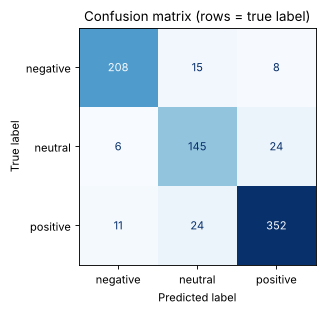

In [21]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred, labels=LABELS), display_labels=LABELS).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (rows = true label)")
plt.tight_layout()

**Reading the confusion matrix:** most mistakes involve the **neutral** class — neutral reviews predicted as positive or
negative, and positive or negative reviews predicted as neutral. Neutral has the lowest F1 in the report above
(about 0.81, against about 0.91 for the other two classes).
That is expected: "the fit is slightly loose but the colour is lovely" is honestly somewhere in between, and even two
human annotators would often disagree. Only about 20 of the 793 test reviews are confused between **positive and
negative** directly.

## 10. Error analysis: read the mistakes

Metrics tell us *how many* mistakes; reading them tells us *why*. Here are misclassified test reviews with the
model's confidence.

In [22]:
proba = best_model.predict_proba(X_test)
classes = list(best_model.classes_)
errors = pd.DataFrame({"review_text": X_test, "true": y_test, "predicted": test_pred,
                       "confidence": proba.max(axis=1).round(2)})
errors = errors[errors["true"] != errors["predicted"]]
print("Misclassified test reviews:", len(errors), "of", len(X_test))
errors.sort_values("confidence", ascending=False).head(12)

Misclassified test reviews: 88 of 793


,review_text,true,predicted,confidence
3414,Bad phone. 🤬,positive,negative,0.92
2462,Bluetooth keeps disconnecting. Not worth it. 👎,positive,negative,0.91
2510,The storage box is okay. The finish is simple. 🤷,negative,neutral,0.91
2797,Could be better. The size is smaller than I thought. 🤷,negative,neutral,0.89
1154,The tablet is okay. Battery backup is average.,negative,neutral,0.88
3100,The shampoo is okay. It is a bit sticky.,positive,neutral,0.87
3802,Okay okay product. Sound is fine for calls.,positive,neutral,0.87
2458,The shirt is okay. The size is as per the chart.,negative,neutral,0.86
471,Keys feel nice to type on. Very light and easy to carry. Value for money.,neutral,positive,0.85
1349,Got many compliments. Really good.,negative,positive,0.84


In [23]:
# Which kinds of review produce the mistakes? (share of test reviews of each kind that are wrong)
kinds = {"contains but/however/although": r"\bbut\b|\bhowever\b|\balthough\b",
         "contains a negation": r"\bnot\b|n't|\bnever\b|\bno\b",
         "Hinglish words": r"accha|bekaar|bakwas|theek|thik|paisa|mast|badhiya|chalega|zabardast|ghatiya",
         "very short (<= 4 words)": None}
wrong = pd.Series(test_pred != y_test.to_numpy(), index=X_test.index)
rows = [{"kind": "all test reviews", "reviews": len(X_test), "error rate": wrong.mean()}]
for k, pat in kinds.items():
    m = X_test.str.split().str.len() <= 4 if pat is None else X_test.str.contains(pat, case=False, regex=True)
    rows.append({"kind": k, "reviews": int(m.sum()), "error rate": wrong[m].mean()})
pd.DataFrame(rows).set_index("kind").round(3)

,reviews,error rate
kind,,
all test reviews,793,0.111
contains but/however/although,110,0.309
contains a negation,176,0.080
Hinglish words,67,0.060
very short (<= 4 words),79,0.025


**What the errors tell us:**
- The most confident mistakes are mostly reviews whose **label looks wrong** when you read them (label noise): "Bad
  phone. 🤬" tagged positive, "Got many compliments. Really good." tagged negative, plain "it's okay" reviews tagged
  positive or negative. The model is actually right; the data is not. In a real project you would send these back for
  re-labelling.
- **Contrast reviews** ("... but ...") have about three times the average error rate: the model adds up positive and
  negative words, but a human reads which part matters more.
- Reviews with a negation and Hinglish reviews are wrong *less* often than average, so keeping stop words and using
  bigrams did their job. Very short reviews are almost always right because they are usually one clear phrase.
- **Sarcasm** ("Wow, stopped working in two days. Amazing quality") uses positive words with a negative meaning; a
  bag-of-words model cannot detect it reliably.

## 11. Which words drive each class?

Logistic Regression learns one weight per term **for each class**. A large positive weight means "this term pushes the
review towards this class".

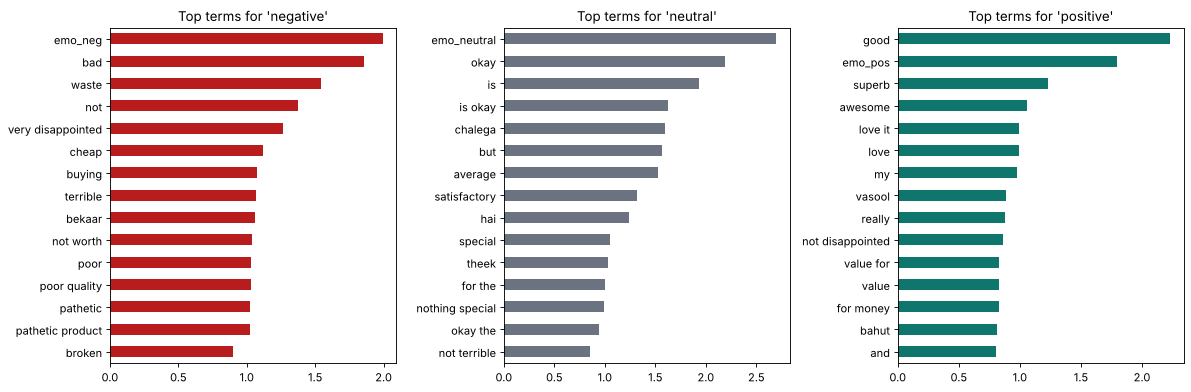

In [24]:
vec = best_model.named_steps["tfidf"]
clf = best_model.named_steps["clf"]
terms = vec.get_feature_names_out()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colours = {"negative": "#b91c1c", "neutral": "#6b7280", "positive": "#0f766e"}
for ax, label in zip(axes, LABELS):
    w = pd.Series(clf.coef_[list(clf.classes_).index(label)], index=terms).sort_values().tail(15)
    w.plot.barh(ax=ax, color=colours[label])
    ax.set_title(f"Top terms for '{label}'")
plt.tight_layout()

The top terms make sense: complaint words and phrases (*waste*, *poor quality*, *not worth*, *bekaar*, `emo_neg`) for
*negative*; *okay*, *average*, *nothing special*, *satisfactory*, Hinglish *theek* / *chalega* and the contrast word *but*
for *neutral*; praise words (*superb*, *love it*, *value for money*, *vasool*) and `emo_pos` for *positive*. Bigrams
appear among the top terms, which confirms they carry information unigrams do not.

For **one** review we can go further: the contribution of a term = its TF-IDF value × its weight for the predicted
class. The API uses exactly this to highlight the words that drove a prediction.

In [25]:
def explain(text, model=best_model, top=6):
    """Return the predicted label, class probabilities and the terms that pushed most towards that label."""
    vec, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    x = vec.transform([text])
    probs = {c: round(float(p), 3) for c, p in zip(clf.classes_, model.predict_proba([text])[0])}
    label = max(probs, key=probs.get)
    weights = clf.coef_[list(clf.classes_).index(label)]
    names = vec.get_feature_names_out()
    contrib = sorted(((str(names[i]), round(float(x[0, i] * weights[i]), 3)) for i in x.nonzero()[1]),
                     key=lambda t: -abs(t[1]))[:top]
    return label, probs, contrib

for text in ["Great screen but the battery dies fast.", "Not worth it. The zip broke on day one."]:
    label, probs, contrib = explain(text)
    print(text, "->", label, probs)
    print("   top terms:", contrib, "\n")

Great screen but the battery dies fast. -> negative {'negative': 0.463, 'neutral': 0.341, 'positive': 0.196}
   top terms: [('but', -0.315), ('battery dies', 0.2), ('dies', 0.194), ('dies fast', 0.194), ('but the', -0.116), ('fast', 0.087)] 

Not worth it. The zip broke on day one. -> negative {'negative': 0.836, 'neutral': 0.079, 'positive': 0.085}
   top terms: [('not worth', 0.256), ('not', 0.178), ('broke', 0.127), ('worth it', 0.119), ('broke on', 0.089), ('day one', 0.089)] 



## 12. Test new reviews and edge cases

In [26]:
new_reviews = [
    "Absolutely love this phone, the camera is superb!",
    "Not bad at all, does the job.",
    "Not worth the money. Stopped working after a week.",
    "It's okay. Nothing special.",
    "Great screen but the battery dies fast.",
    "Bahut accha product, paisa vasool 😍",
    "bekaar quality 👎",
    "Wow, amazing quality... broke on the first day 🙄",      # sarcasm
    "The delivery guy was rude.",                            # not about the product at all
    "asdfgh",                                                 # nonsense: no known words
    "The car's engine is powerful and smooth",               # different domain (cars)
]
out = []
for text in new_reviews:
    label, probs, contrib = explain(text, top=3)
    out.append({"review": text, "predicted": label, "confidence": max(probs.values()),
                "top terms": ", ".join(t for t, _ in contrib)})
pd.DataFrame(out)

,review,predicted,confidence,top terms
0,"Absolutely love this phone, the camera is superb!",positive,0.572,"superb, love, camera is"
1,"Not bad at all, does the job.",neutral,0.583,"job, the job, does the"
2,Not worth the money. Stopped working after a week.,negative,0.799,"not worth, not, the money"
3,It's okay. Nothing special.,neutral,0.909,"okay, special, nothing special"
4,Great screen but the battery dies fast.,negative,0.463,"but, battery dies, dies"
5,"Bahut accha product, paisa vasool 😍",positive,0.875,"emo_pos, vasool, paisa vasool"
6,bekaar quality 👎,negative,0.893,"emo_neg, bekaar, quality"
7,"Wow, amazing quality... broke on the first day 🙄",negative,0.556,"broke, quality, amazing"
8,The delivery guy was rude.,positive,0.426,"delivery, the, was"
9,asdfgh,negative,0.377,


**Things to notice in the table above:**
- Clear positive, negative and neutral reviews, "not worth the money" and the Hinglish reviews are tagged correctly.
  "Not bad at all, does the job." comes out **neutral**, which is a reasonable reading.
- Confidence is often moderate (for example about 0.57 for the clearly positive first review). With a small `C` the
  model is cautious; treat the probabilities as a ranking of how sure it is, not as exact chances.
- The mixed review "Great screen but the battery dies fast." is tagged negative with **less than 0.5** confidence:
  the model is honestly unsure, and the API flags such results as *low confidence*.
- The **sarcastic** review is tagged negative, but only because of the word *broke*; *amazing* still pulls the other way.
- **Out of scope:** "The delivery guy was rude." is tagged **positive** (wrong) with low confidence: none of its words
  are complaint words the model learned. The car review is tagged positive, but the model has never seen cars.
- For the **nonsense** text "asdfgh" there are no known terms at all (empty `top terms`), so the prediction comes only
  from the model's intercepts. The API returns `known_terms: 0` in that case so the user can see the model is guessing.

## 13. Save the model and the information the API needs

We save the **whole pipeline** (TF-IDF with `clean_text` + Logistic Regression), so the API passes raw text and gets
probabilities back. `joblib` stores a *reference* to `text_utils.clean_text`, which is why the API needs
`backend/text_utils.py` next to `app.py`.

`sentiment_info.json` stores the labels, limits for validation, test metrics and example reviews for the frontend.

In [27]:
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/sentiment_model.joblib")

report = classification_report(y_test, test_pred, labels=LABELS, output_dict=True)
info = {
    "model_name": "Logistic Regression + TF-IDF word 1-2 grams",
    "labels": LABELS,
    "C": float(C_best),
    "vocabulary_size": int(len(terms)),
    "cv_macro_f1": round(float(grid.best_score_), 3),
    "test_metrics": {
        "macro_f1": round(float(test_macro_f1), 3),
        "accuracy": round(float(test_acc), 3),
        "per_class_f1": {c: round(report[c]["f1-score"], 3) for c in LABELS},
    },
    "baseline_test_macro_f1": round(float(f1_score(y_test, base_pred, average="macro")), 3),
    "low_confidence_below": 0.5,
    "max_chars": 2000,
    "max_batch": 50,
    "train_rows": int(len(X_train)),
    "examples": [
        "The battery lasts all day and the camera takes lovely photos. Highly recommend it!",
        "Not bad at all. The fabric is soft and comfortable.",
        "It's okay. The size is smaller than I thought.",
        "Great screen but the battery dies fast.",
        "Stopped working after a week. Not worth the money.",
        "Bekaar product, paisa barbaad 👎",
    ],
}
with open("models/sentiment_info.json", "w", encoding="utf-8") as f:
    json.dump(info, f, indent=2, ensure_ascii=False)
print(json.dumps(info["test_metrics"], indent=2))
print(sorted(os.listdir("models")))

{
  "macro_f1": 0.878,
  "accuracy": 0.889,
  "per_class_f1": {
    "negative": 0.912,
    "neutral": 0.808,
    "positive": 0.913
  }
}
['sentiment_info.json', 'sentiment_model.joblib']


In [28]:
# Reload from disk exactly as the API will, and check the probabilities match
reloaded = joblib.load("models/sentiment_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test.head(20)), best_model.predict_proba(X_test.head(20)))
print("Reloaded model gives identical probabilities.")

Reloaded model gives identical probabilities.


## 14. Limitations and possible improvements

- **Synthetic data.** The reviews come from templates, so the vocabulary is smaller and more regular than real reviews.
  Expect lower scores on real data and always evaluate on a real labelled sample first.
- **Sarcasm and irony** ("Amazing quality... broke on day one") need context a bag-of-words model does not have.
- **Mixed reviews** are hard: the model adds up word weights but cannot tell which aspect the customer cares about most.
  Aspect-based sentiment (one label per aspect: battery, screen, delivery) would be more useful for product teams.
- **Domain shift.** Words mean different things in different domains ("unpredictable" is bad for a phone, good for a
  film plot). A model trained on product reviews should not be used on other text without re-checking.
- **Language mix.** Only a handful of Hinglish words appear in training. Real Hinglish (and other languages, scripts,
  and spelling variants such as "acha/accha/achha") would need more labelled data or a multilingual model.
- **Label noise** limits the best possible score; cleaning labels can help more than a fancier model.
- **Improvements to try:** combine word and char n-grams with `FeatureUnion`, calibrate Linear SVM with
  `CalibratedClassifierCV` to get probabilities, add the star rating as a feature when it is available, and compare with
  a pre-trained transformer (Batch 2 Module 08).

**Next step:** start the Flask API in `backend/` (see the project README). It loads the two files saved above.